# Análise do Problema de Regressão

Neste notebook é analisado o problema de previsão do Burnout Score, uma variável numérica contínua relacionada ao nível de burnout dos indivíduos.

## Carregamento do dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_clean = pd.read_csv(
    "../datasets/dataset_clean.csv"
)

df_clean.head()

,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.0,67,Hybrid,...,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.0,44,Hybrid,...,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.0,60,No,...,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.0,25,Yes,...,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,6231.0,52,No,...,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


# Definição da Variável-Alvo para Regressão

A variável escolhida como alvo é `Burnout_Score`.

Ela foi escolhida porque representa uma pontuação numérica contínua relacionada ao nível de burnout. Por ser uma variável quantitativa, pode ser utilizada em um problema de regressão para prever seu valor a partir das demais características disponíveis no dataset.

# Estatísticas Descritivas do Burnout Score

In [2]:
print("Média:", df_clean["Burnout_Score"].mean())
print("Mediana:", df_clean["Burnout_Score"].median())
print("Desvio padrão:", df_clean["Burnout_Score"].std())
print("Mínimo:", df_clean["Burnout_Score"].min())
print("Máximo:", df_clean["Burnout_Score"].max())

display(
    df_clean["Burnout_Score"].describe()
)

Média: 40.20188
Mediana: 39.0
Desvio padrão: 26.223120285472326
Mínimo: 0
Máximo: 100


count    50000.00000
mean        40.20188
std         26.22312
min          0.00000
25%         19.00000
50%         39.00000
75%         59.00000
max        100.00000
Name: Burnout_Score, dtype: float64

# Distribuição do Burnout Score

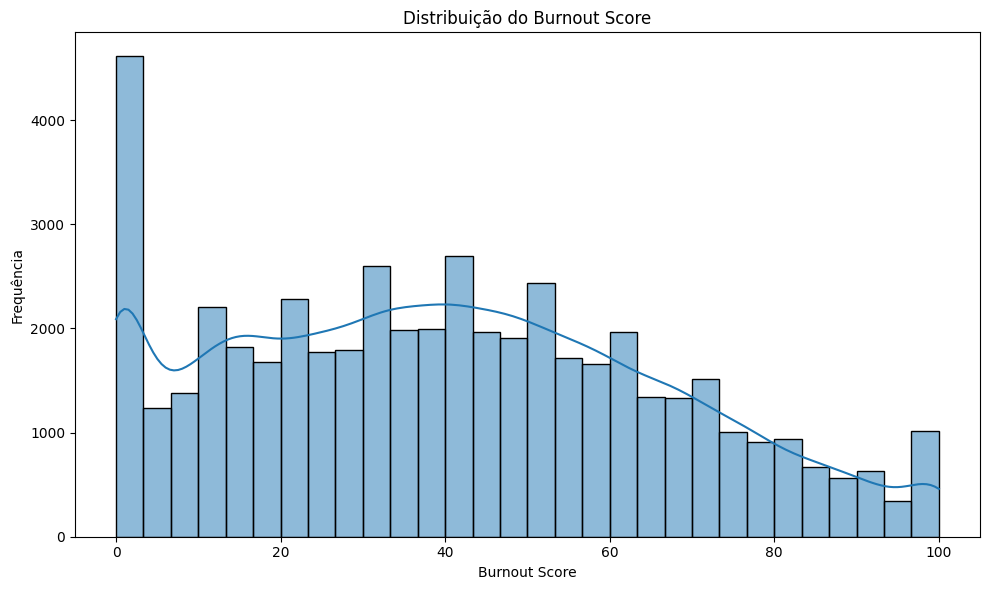

In [3]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="Burnout_Score",
    bins=30,
    kde=True
)

plt.title("Distribuição do Burnout Score")
plt.xlabel("Burnout Score")
plt.ylabel("Frequência")

plt.tight_layout()

plt.savefig(
    "../reports/figures/burnout_score_distribution.png",
    dpi=300
)

plt.show()

# Correlação das Variáveis com o Burnout Score

In [4]:
correlacao = df_clean.select_dtypes(
    include=np.number
).corr()

correlacao_burnout = (
    correlacao["Burnout_Score"]
    .sort_values(ascending=False)
)

display(correlacao_burnout)

Burnout_Score              1.000000
Anxiety_Score              0.917360
Depression_Score           0.903550
Work_Hours_Per_Week        0.607838
Screen_Time_Hours          0.346543
Coffee_Cups_Per_Day        0.263934
Social_Media_Hours         0.008596
Age                        0.000229
Work_Life_Balance          0.000059
Life_Satisfaction         -0.001228
Monthly_Income_USD        -0.001353
Job_Satisfaction          -0.001633
Gaming_Hours              -0.002196
Absenteeism_Days          -0.003969
Person_ID                 -0.005055
Physical_Activity_Hours   -0.187650
Sleep_Hours               -0.219589
Meditation_Minutes        -0.230205
Productivity_Score        -0.884935
Mood_Score                -0.908323
Emotional_Stability       -0.909691
Name: Burnout_Score, dtype: float64

# Relação entre Horas de Trabalho e Burnout Score

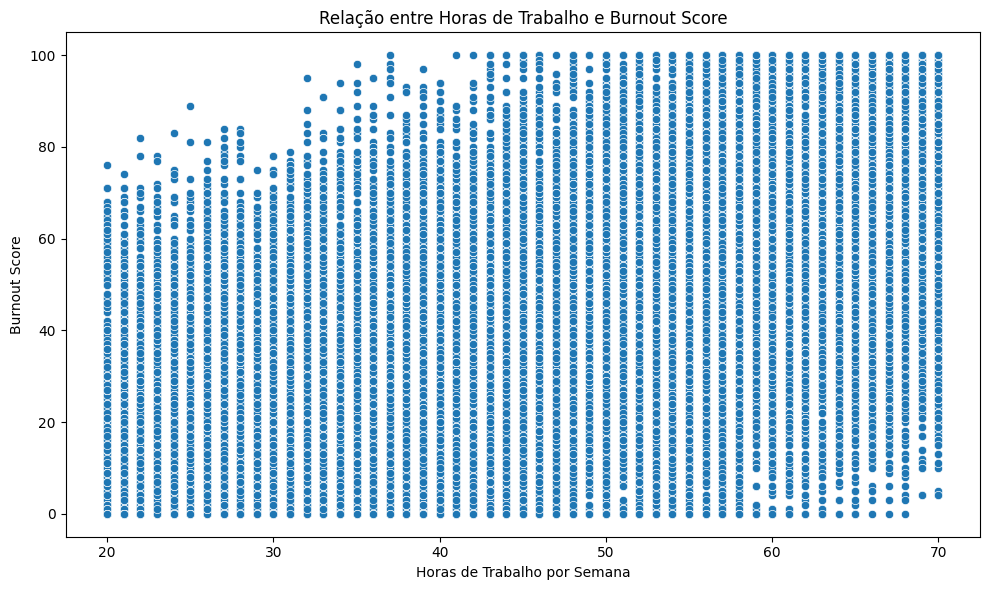

In [5]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Work_Hours_Per_Week",
    y="Burnout_Score"
)

plt.title(
    "Relação entre Horas de Trabalho e Burnout Score"
)

plt.xlabel("Horas de Trabalho por Semana")
plt.ylabel("Burnout Score")

plt.tight_layout()

plt.savefig(
    "../reports/figures/burnout_vs_work_hours.png",
    dpi=300
)

plt.show()

# Principais Variáveis Relacionadas ao Burnout Score

In [6]:
principais_features_regressao = [
    "Anxiety_Score",
    "Depression_Score",
    "Mood_Score",
    "Emotional_Stability",
    "Productivity_Score",
    "Work_Hours_Per_Week"
]

correlacoes_principais = correlacao_burnout[
    principais_features_regressao
]

display(
    correlacoes_principais
)

Anxiety_Score          0.917360
Depression_Score       0.903550
Mood_Score            -0.908323
Emotional_Stability   -0.909691
Productivity_Score    -0.884935
Work_Hours_Per_Week    0.607838
Name: Burnout_Score, dtype: float64

# Análise de Multicolinearidade

Foram identificadas correlações muito elevadas entre algumas variáveis independentes. Entre os principais casos estão Anxiety_Score e Emotional_Stability, Mood_Score e Productivity_Score, além de Anxiety_Score e Mood_Score.

Essa multicolinearidade deve ser considerada principalmente em modelos lineares, pois variáveis altamente correlacionadas podem dificultar a interpretação dos coeficientes.

In [7]:
pares_multicolinearidade = {
    "Anxiety_Score × Emotional_Stability":
        correlacao.loc["Anxiety_Score", "Emotional_Stability"],

    "Mood_Score × Productivity_Score":
        correlacao.loc["Mood_Score", "Productivity_Score"],

    "Anxiety_Score × Mood_Score":
        correlacao.loc["Anxiety_Score", "Mood_Score"]
}

for par, valor in pares_multicolinearidade.items():
    print(f"{par}: {valor:.3f}")

Anxiety_Score × Emotional_Stability: -0.976
Mood_Score × Productivity_Score: 0.955
Anxiety_Score × Mood_Score: -0.924


# Variáveis que Não Devem ser Utilizadas como Preditoras

Para evitar problemas de identificação, vazamento de informação e utilização de variáveis que não representam características preditivas, as seguintes variáveis não serão utilizadas como features:

- `Person_ID`: identificador do indivíduo.
- `Burnout_Risk`: classificação diretamente relacionada ao burnout e utilizada no problema de classificação.
- `AI_Wellness_Recommendation`: pode representar uma recomendação derivada de outras informações do indivíduo.

# Recomendações de Algoritmos de Regressão

Como etapa inicial de modelagem, recomenda-se testar:

- Regressão Linear;
- Ridge;
- Lasso;
- Random Forest Regressor;
- Gradient Boosting Regressor.

A comparação entre modelos lineares e modelos baseados em árvores é interessante devido às fortes correlações observadas e à presença de multicolinearidade.

# Conclusões da Análise de Regressão

O `Burnout_Score` apresenta relações fortes com variáveis como Anxiety_Score, Depression_Score, Mood_Score, Emotional_Stability e Productivity_Score. As horas de trabalho também apresentam relação positiva relevante com o nível de burnout.

As principais dificuldades para a modelagem são a presença de valores que precisaram ser tratados e a multicolinearidade entre algumas variáveis. Como próximos passos, recomenda-se comparar modelos lineares e algoritmos baseados em árvores utilizando métricas apropriadas de regressão.